In [1]:
import sys
print(sys.executable)
sys.path.append('/home/nhewko/FEniCS/swelling/vf-swelling-fiber')
sys.path.append('/home/nhewko/FEniCS/swelling/vf-exputils')
sys.path.append('/home/nhewko/FEniCS/swelling/vf-fem')
sys.path.append('/home/nhewko/FEniCS/swelling/nonlinear-equation')
sys.path.append('/home/nhewko/FEniCS/vf-onset-sensitivity/src/libhopf')
sys.path.append('/home/nhewko/FEniCS/vf-onset-sensitivity/')
import libhopf

/home/nhewko/miniconda3/envs/fenics-env/bin/python


# Baseline Parameters Definition

In [2]:
import itertools
import os, sys
from pprint import pprint
from typing import Mapping, Any, List, Tuple, Union
from tqdm.notebook import tqdm

import numpy as np
import scipy.signal as signal
import dolfin as dfn
import ufl
import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import tri
# pandas used for exporting values to csv
import pandas as pd
# re used for substrings (getting Escar from simulation name) 
import re

from femvf import forward, statefile as sf, meshutils
from femvf.models.transient import solid, fluid
from femvf.models.dynamical import (solid as dsolid, fluid as dfluid)
from femvf.postprocess import solid as slsig
from femvf import static
from femvf.load import load_transient_fsi_model, load_dynamical_fsi_model

from blockarray import blockvec

from vfsig import modal, fftutils, clinical

from exputils import h5utils, exputils, postprocutils
import scar

sys.path.append('../vf-onset-sensitivity')
import libhopf

SAVE_FIGS = False
dfn.set_log_level(50)

ExpParam = scar.ExpParam

## Default parameter values
# Change values here to reflect recently run simulations
# (can refer to output folder to obtain values) 
PARAMS_DEFAULT = ExpParam({
    'MeshName': 'BCS_S',
    'SD': 0.08,
    'DZ': 0.00, # Spacing in Z axis
    'NZ': 1, # Number of segments in Z direction
    'clscale': 0.25,
    'Ecov': 2.5e4, # Ecover (Pa)
    'Ebod': 5e4, # Ebody (Pa)
    'ModScar': 10, # Scarring Modifier
    'Eta': 5, # Viscosity
    'psub': 0.3e3 * 10, # Subglottal pressure (kPa)
    'dt': 10e-5, # Timestep size
    'tf': 0.5, # Simulation end time 
    'ModifyEffect': '',
    'SwellingDistribution':'uniform'
})

VCOVS = np.array([1.0])
MCOVS = np.array([0])
# ESCARS = np.array([1e5])

CL_SCALES = [0.05, 0.125, 0.25, 0.5]
MESH_NAMES = ["BCS_M", "BCS_S", "BCS_I"]
SCAR_DIAS = np.array([0, 0.08])

# set output file location 
OUT_DIR = 'out'
POST_DIR = OUT_DIR

#set variables for saving images to svg
FIG_DIR = 'fig'
FIG_EXT = 'svg'

def iter_params(
    
        params: Mapping[str, Union[List[Any], Any]],
        default_params: ExpParam=PARAMS_DEFAULT
    ):
    """
    Return an iterator over `ExpParam` instances

    Parameters
    ----------
    params :
        A mapping from parameter labels to parameter value(s). Parameter
        instances are created for each parameter value given in the dictionary.
    defaults : ExpParam
        Default values for unspecified parameters
    """
    # Validate that all kwargs keys are valid parameters
    keys = list(params.keys())
    for key in keys:
        assert key in default_params

    # Make sure all parameter values are lists
    # This is so that you can iterate over them
    def _require_list(x):
        if isinstance(x, (list, tuple, np.ndarray)):
            return x
        else:
            return [x]

    _params = {
        key: _require_list(values)
        for key, values in params.items()
    }

    def _param(params):
        x = default_params.data.copy()
        x.update(params)
        return type(default_params)(x)

    for args in itertools.product(*list(_params.values())):
        yield (
            _param({key: val for key, val in zip(keys, args)})
        )

def load_measures(
        data: Mapping[str, Any],
        measure_name: str,
        params: Mapping[str, Union[List[Any], Any]],
        default_params: ExpParam=PARAMS_DEFAULT
    ):
    """
    Return measures for each supplied parameter(s)

    Parameters
    ----------
    data :
        A mapping from simuations ids/measure names to values
    measure_name : str
        A measure name to load
    params :
        A mapping from parameter labels to parameter value(s). Measurements
        are extracted from these parameters.
    defaults :
        Default values for unspecified parameters
    """
    keys = list(params.keys())
    vals = [
        data[f'{param.to_str()}/{measure_name}']
        for param in iter_params(params, default_params=default_params)
        
    ]
    if len(vals) == 1:
        return vals[0]
    else:
        return vals

def load_measures_np(
        data: Mapping[str, Any],
        measure_name: str,
        params: Mapping[str, Union[List[Any], Any]],
        default_params: ExpParam=PARAMS_DEFAULT
    ):
    """
    Return measures for each supplied parameter(s) (see `load_measures`)

    This functions returns outputs in a numpy array
    """
    return np.array(load_measures(data, measure_name, params, default_params))



## Load post-processed results

In [3]:
SIGNALS = {}

## Load simulation results, if error with case_names later, delete postprocess.h5 and run simulations again to clear "cached" simulations in POST_DIR folder
with h5py.File(f'{POST_DIR}/postprocess.h5', mode='r') as f:
    SIGNALS = h5utils.h5_to_dict(f, SIGNALS)
    

In [4]:
# Get a text summary of what cases were run and what measures were processed
from pprint import pprint
# case_names refer to each of the simulation names, the long file names in the "out" folder
case_names = [key.split('/')[0] for key in SIGNALS.keys()]
case_names = list(set(case_names))

# List of parameters that are saved in each simulation (mostly output parameters)
meas_names = [key.split('/')[1] for key in SIGNALS.keys()]
meas_names = list(set(meas_names))

## Loading Model Info

In [5]:
# Generate empty arrays for mesh names and scar diameters in study, automatically populated to avoid having to recopy from python code
MeshNames = []
ScarDias = []
CLScales = []
deltaTs = []

# Iterate through all the cases in the "out" folder (but not in subfolders)
for case_name in tqdm(case_names):
    # Check if the current mesh name (mesh type) is not in the list of cases
    if scar.ExpParam(case_name)['MeshName'] not in MeshNames:
        MeshNames.append(scar.ExpParam(case_name)['MeshName'])

    if scar.ExpParam(case_name)['SD'] not in ScarDias:
        ScarDias.append(scar.ExpParam(case_name)['SD'])
    
    if scar.ExpParam(case_name)['clscale'] not in CLScales:
        CLScales.append(scar.ExpParam(case_name)['clscale'])

    if scar.ExpParam(case_name)['dt'] not in deltaTs:
        deltaTs.append(scar.ExpParam(case_name)['dt'])
        

# Sort SD array from smallest to largest to be proper and avoid issues with plotting
SD_sorted = np.stack((ScarDias), axis=0)
np_ScarDias = SD_sorted[SD_sorted.argsort()][::1]

CL_sorted = np.stack((CLScales), axis=0)
np_CLScales = CL_sorted[CL_sorted.argsort()][::1]

dt_sorted = np.stack((deltaTs), axis=0)
np_dt = dt_sorted[dt_sorted.argsort()][::1]

# Copy sorted numpy SD array to the regular SD array, required for searching
for itr in range(0, len(ScarDias), 1):
    ScarDias[itr] = float(np_ScarDias[itr])
for itr in range(0, len(CLScales), 1):
    CLScales[itr] = float(np_CLScales[itr])
for itr in range(0, len(deltaTs), 1):
    deltaTs[itr] = float(np_dt[itr])

PARAMS = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
CASE_NAMES = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]

MODEL = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
XREF = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
SDOF_TO_VERT = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
VERT_TO_VDOF = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
VERT_TO_SDOF = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
MESH = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
CELLS = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
dofs_med = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
VERT_MED = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
# mf_cell = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
# mv_cell = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
CELLS_COVER = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
CELLS_BODY = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]

VERT_MED = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
VERT_INT = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
VERT_SCAR_INT = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))] # scar vertices along interface
VERT_SCAR_BORDER = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))] # scar vertices along interface and at cover 
VERT_SCAR = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))] # all vertices in scar region
CELLS_SCAR = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]

# verts_cover = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
# verts_body = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
# verts_interface = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
_xy = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
idx_interface = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
VERT_INT = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
V_CG1 = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
DOFMAP_CG1 = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
V_DG0 = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
DOFMAP_DG0 = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]


for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        for iT in range(0, len(deltaTs)):

            PARAMS[iS][iC][iT] = PARAMS_DEFAULT.substitute({
                # Obtaining value from index of each property to avoid using "MeshNames.index(iM)" for every index call
                'clscale': CLScales[iC],
                'dt': deltaTs[iT], 
                'SD': ScarDias[iS]
            })
            # Substituting default meshname and scardia values with the currently iterated ones
            MODEL[iS][iC][iT] = scar.setup_model(PARAMS[iS][iC][iT])
    
            # Load these mesh related constants for plotting configurations
            XREF[iS][iC][iT] = MODEL[iS][iC][iT].solid.XREF
            SDOF_TO_VERT[iS][iC][iT] = dfn.dof_to_vertex_map(MODEL[iS][iC][iT].solid.residual.form['coeff.fsi.p1'].function_space())
            VERT_TO_VDOF[iS][iC][iT] = dfn.vertex_to_dof_map(MODEL[iS][iC][iT].solid.residual.form['coeff.state.u1'].function_space())
            VERT_TO_SDOF[iS][iC][iT] = dfn.vertex_to_dof_map(MODEL[iS][iC][iT].solid.residual.form['coeff.fsi.p1'].function_space())
            MESH[iS][iC][iT] = MODEL[iS][iC][iT].solid.residual.mesh()
            CELLS[iS][iC][iT] = MESH[iS][iC][iT].cells()
            
            dofs_med[iS][iC][iT] = np.concatenate([fsimap.dofs_solid for fsimap in MODEL[iS][iC][iT].fsimaps])
            VERT_MED[iS][iC][iT] = SDOF_TO_VERT[iS][iC][iT][MODEL[iS][iC][iT].fsimaps[0].dofs_solid]
            
            ## Get all vertices on the body-cover interface
            mf_cell = MODEL[iS][iC][iT].solid.residual.mesh_function('cell')
            mv_cell = MODEL[iS][iC][iT].solid.residual.mesh_function_label_to_value('cell')
            
            if 'inferior' in mv_cell:
                CELLS_COVER[iS][iC][iT] = np.concatenate([
                    mf_cell.where_equal(mv_cell['inferior']),
                    mf_cell.where_equal(mv_cell['medial']),
                    mf_cell.where_equal(mv_cell['superior'])
                ])
            elif 'cover' in mv_cell:
                CELLS_COVER[iS][iC][iT] = mf_cell.where_equal(mv_cell['cover'])
            else:
                assert False

            CELLS_BODY[iS][iC][iT] = mf_cell.where_equal(mv_cell['body'])
            
            verts_cover = CELLS[iS][iC][iT][CELLS_COVER[iS][iC][iT]].reshape(-1)
            verts_body = CELLS[iS][iC][iT][mf_cell.where_equal(mv_cell['body'])].reshape(-1)
            verts_interface = np.array(list(set(verts_cover).intersection(set(verts_body))))

            if 'scar' in mv_cell:
                CELLS_SCAR[iS][iC][iT] = mf_cell.where_equal(mv_cell['scar'])
                verts_scar = CELLS[iS][iC][iT][CELLS_SCAR[iS][iC][iT]].reshape(-1)
                verts_scar_interface = np.array(list(set(verts_cover).intersection(set(verts_scar))|set(verts_body).intersection(set(verts_scar))))
                
                VERT_SCAR[iS][iC][iT] = MESH[iS][iC][iT].coordinates()[verts_scar]
                VERT_SCAR_INT[iS][iC][iT] = MESH[iS][iC][iT].coordinates()[verts_scar_interface]
                
                max_x = max(VERT_SCAR[iS][iC][iT][:,0])
                max_y = max(VERT_SCAR[iS][iC][iT][:,1])
                vert_scar_sort = meshutils.sort_vertices_by_nearest_neighbours(VERT_SCAR_INT[iS][iC][iT], np.array([max_x,max_y]))
                VERT_SCAR_INT[iS][iC][iT] = VERT_SCAR_INT[iS][iC][iT][vert_scar_sort]
                
                mf_facet = MODEL[iS][iC][iT].solid.residual.mesh_function('facet')
                mv_facet = MODEL[iS][iC][iT].solid.residual.mesh_function_label_to_value('facet')
    
                verts_pressure = []
                for facet in dfn.facets(MESH[iS][iC][iT]):
                    facet_idx = facet.index()
                    if mf_facet[facet_idx] == mv_facet['pressure']:
                        facet_verts = facet.entities(0)
                        verts_pressure.append(facet_verts[0])
                        verts_pressure.append(facet_verts[1])
                verts_pressure = list(set(verts_pressure))
                
                verts_scar_pressure = np.array(list(set(verts_scar).intersection(set(verts_pressure))))
    
                VERT_SCAR_BORDER[iS][iC][iT] = np.concatenate((VERT_SCAR_INT[iS][iC][iT], MESH[iS][iC][iT].coordinates()[verts_scar_pressure]), axis=0)           
                vert_scar_sort = meshutils.sort_vertices_by_nearest_neighbours(VERT_SCAR_BORDER[iS][iC][iT], np.array([max_x,max_y]))
                VERT_SCAR_BORDER[iS][iC][iT] = VERT_SCAR_BORDER[iS][iC][iT][vert_scar_sort]
            
            _xy[iS][iC][iT] = MESH[iS][iC][iT].coordinates()[verts_interface]
            idx_interface[iS][iC][iT] = meshutils.sort_vertices_by_nearest_neighbours(_xy[iS][iC][iT])
            VERT_INT[iS][iC][iT] = verts_interface[idx_interface[iS][iC][iT]]
            
            V_CG1[iS][iC][iT] = dfn.FunctionSpace(MESH[iS][iC][iT], 'CG', 1)
            DOFMAP_CG1[iS][iC][iT] = V_CG1[iS][iC][iT].dofmap()
            V_DG0[iS][iC][iT] = dfn.FunctionSpace(MESH[iS][iC][iT], 'DG', 0)
            DOFMAP_DG0[iS][iC][iT] = V_DG0[iS][iC][iT].dofmap()

  0%|          | 0/24 [00:00<?, ?it/s]

/home/nhewko/FEniCS/swelling/vf-fem/femvf/meshutils.py:96: UserWarning: Loading 'gmsh' mesh from existing '.xdmf' files.
  warnings.warn(


Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.
Expecting bilinear form.


In [6]:
import scipy.signal as signal
def normal(x):
    """
    Return the normal vector to a 2D curve `x`
    """
    assert x.ndim == 2
    assert x.shape[-1] == 2

    dx = np.zeros(x.shape)
    dx[1:, :] = x[1:] - x[:-1]
    s = np.cumsum(np.linalg.norm(dx, axis=-1))

    # Tangent
    dx = np.gradient(x[:, 0], s, axis=0)
    dy = np.gradient(x[:, 1], s, axis=0)

    # Non-unit normal
    nx = dy
    ny = -dx
    n = np.stack([nx, ny], axis=-1)
    return n/np.linalg.norm(n, axis=-1, keepdims=True)

def offset_normal(x, n):
    return x + n

def tavg(y, t, axis=-1):
    """
    Return the time average of a signal
    """
    # tavg_y = np.trapz(y, x=t, axis=axis)/np.trapz(np.ones(t.shape), x=t, axis=axis)
    tavg_y = np.trapezoid(y, x=t, axis=axis)/np.trapezoid(np.ones(t.shape), x=t, axis=axis)
    return tavg_y

def make_solve_static(model):
    """
    Return the static state for a solid model with no external loading
    """
    forms = model.solid.forms
    f1uva = forms['form.un.f1uva']
    u1 = forms['coeff.state.u1']
    bc_dir = forms['bc.dirichlet']

    def solve_static():
        dfn.solve(f1uva==0, u1, bcs=[bc_dir])
        x = model.state1.copy()
        x['v'][:] = 0
        x['a'][:] = 0
        return x
    return solve_static

## Setup function to compute SPL from t/q

def proc_prms(t, q):
    """
    Return the RMS radiated pressure at 1m using a piston-in-baffle approximation
    """
    dt = t[1]-t[0]

    # Assume a 2cm vocal fold length
    # This is needed to get a true flow rate since the 1D model flow rate
    # is over one dimension
    piston_params = {
        'r': 100.0,
        'theta': 0.0,
        'a': 1.0,
        'rho': 0.001225,
        'c': 343*100
    }
    VF_LENGTH = 2
    win = signal.windows.tukey(q.size, alpha=0.15)
    wq = win*q*VF_LENGTH
    fwq = np.fft.rfft(wq)
    freq = np.fft.rfftfreq(wq.size, d=dt)

    fwp = clinical.prad_piston(fwq, f=freq*2*np.pi, piston_params=piston_params)

    # This computes the squared sound pressure
    psqr = fftutils.power_from_rfft(fwp, fwp, n=fwq.size)

    # The rms pressure in units of Pa
    prms = np.sqrt(psqr/fwp.size)

    return prms

def get_dx(model, name=None):
    cell_label_to_id = model.solid.residual.mesh_function_label_to_value('cell')
    _dx = model.solid.residual.measure('dx')
    if name is None:
        dx = _dx
    elif name == 'cover':
        # dx = (
        #     _dx(int(cell_label_to_id['inferior']))
        #     +_dx(int(cell_label_to_id['medial']))
        #     + _dx(int(cell_label_to_id['superior']))
        # )
        dx = _dx(int(cell_label_to_id['cover']))
    elif name == 'scar':
        dx = _dx(int(cell_label_to_id['scar']))
    else:
        dx = _dx(int(cell_label_to_id[name]))
    return dx

# Figures
## Figure constants

Converts the output figure names to a manuscript ordered names (Fig1, Fig2, ...)

In [7]:
fig_names = [
    'SwelledGeometryVsV',
    'CoverMassVsV',
    'F0VsV',
    'ContactVMCycleDynamicsVsV',
    'StressFieldvsV',
    'AvgVMStressVsV'
]

## Set any figure constants
FIG_TYPE = 'manuscript'
# FIG_TYPE = 'presentation'

CM = 1/2.54
if FIG_TYPE == 'manuscript':
    FIG_DIR = 'fig/manuscript'
    FIG_EXT = 'pdf'

    FIG_LX = 8.4*CM
    FIG_LX_WIDE = 17.4*CM

    FIG_LY = 23.4*CM
    FONTSIZE = 9
elif FIG_TYPE == 'presentation':
    FIG_DIR = 'fig/presentation'
    FIG_EXT = 'svg'

    FIG_LX = 7.5*CM
    FIG_LX_WIDE = 30*CM

    FIG_LY = 13*CM
    FONTSIZE = 12

SIZE_SMALL = (FIG_LX, FIG_LX)
SIZE_MED = (FIG_LX, 1.25*FIG_LX)
SIZE_MED_WIDE = (FIG_LX_WIDE, 1.25*FIG_LX)
SIZE_LARGE = (FIG_LX, 1.5*FIG_LX)
SIZE_LARGE_WIDE = (FIG_LX_WIDE, 1.5*FIG_LX)

DPI = 250

# Colors
COLOR_CYCLE = plt.rcParams['axes.prop_cycle'].by_key()['color']
MARKER_CYCLE = ['.', '*', 'x', 'o']
LS_CYCLE = ['-', '-.', ':', '--', (0, (1, 4))]

mpl.rcParams.update({
    'figure.dpi': 200,
    'font.size': FONTSIZE,
    'text.usetex': False,
    'legend.handlelength': 2,
    'text.latex.preamble': (
        r'\usepackage{amsmath}'
        r'\usepackage{siunitx}'
        r'\usepackage{sansmath}'
        r'\sansmath'
        r'\sisetup{detect-all}'
        r'\newcommand{\avg}[1]{\underset{#1}{\mathrm{avg}} \, }'
    )
})
# mpl.rcParams['']

## Functions for plotting percent change
def per_change_forward(y, y0):
    return (y-y0)/y0 * 100

def per_change_inv(y, y0):
    return y*y0/100 + y0

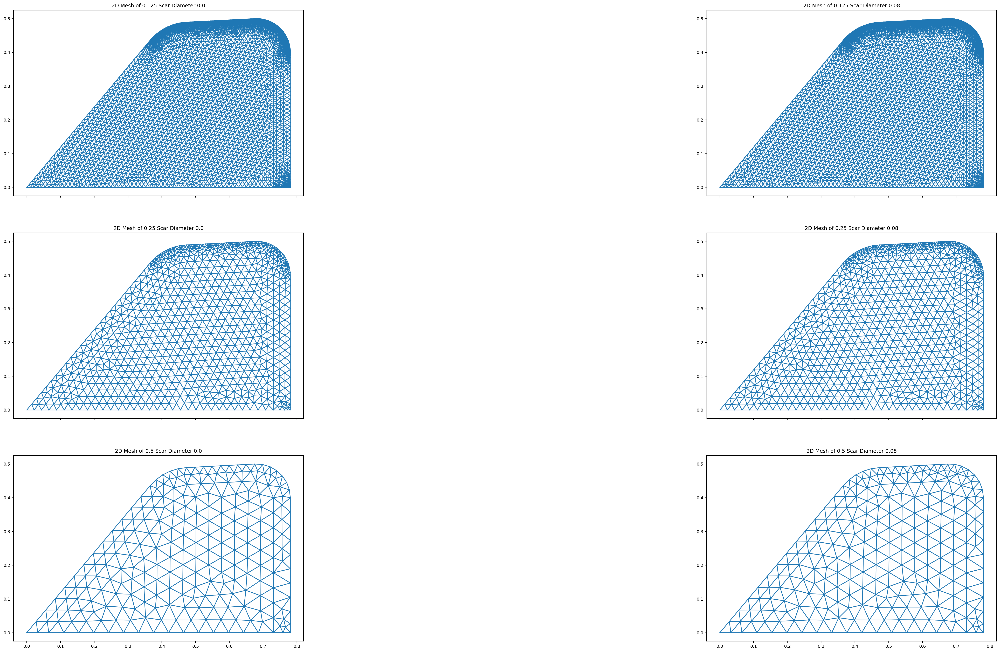

In [8]:
from femvf.meshutils import extract_zplane_facets
# facets = [[0 for i in range(len(CLScales))] for j in range(len(ScarDias))]
# facets_idx = [[0 for i in range(len(CLScales))] for j in range(len(ScarDias))]

facets = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
facets_idx = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]

# Create grid of subplots to display meshes (at least for testing purposes)
fig, axs = plt.subplots(len(CLScales), len(ScarDias), sharex=True, sharey=False, figsize=(48, 24))


for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        # Get mesh from model
        facets[iS][iC][0] = extract_zplane_facets(MESH[iS][iC][0], 1.5/10)
        facets_idx[iS][iC][0] = [facet.index() for facet in facets[iS][iC][0]]

        from matplotlib.tri import Triangulation
        
        # Extract full triangle data
        cells = MESH[iS][iC][0].cells()
        coords = MESH[iS][iC][0].coordinates()

        # TODO Would be nice to have scar region coloured differently
        axs[iC, iS].triplot(coords[:, 0], coords[:, 1], triangles=cells)
        axs[iC, iS].set_aspect('equal')
        axs[iC, iS].set_title("2D Mesh of " + str(CLScales[iC]) + " Scar Diameter " + str(ScarDias[iS]))

if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/Meshes.{FIG_EXT}')

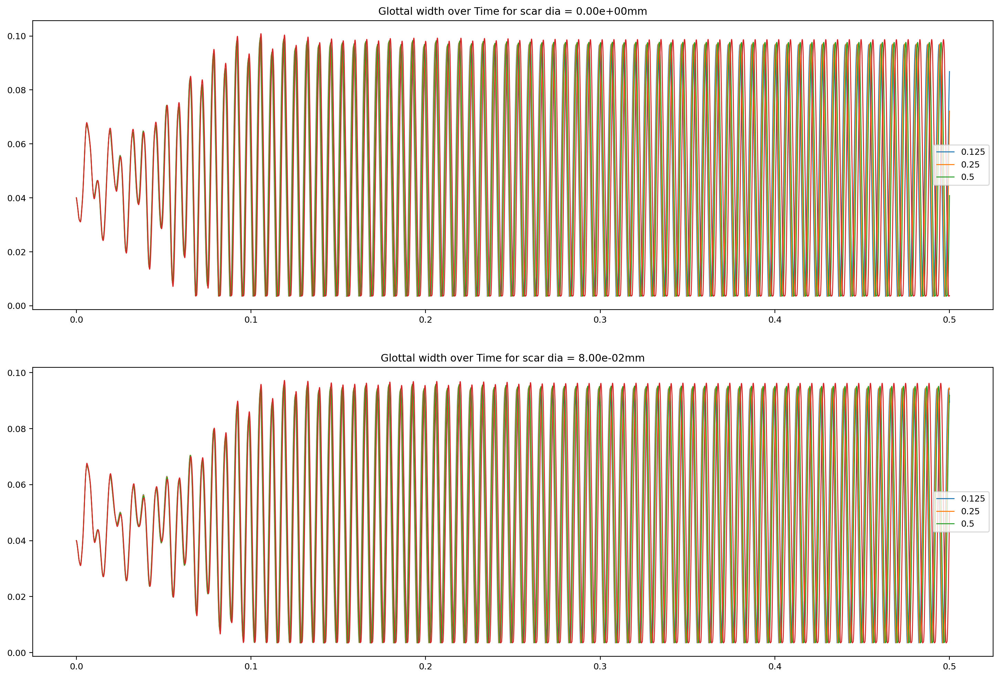

In [9]:
# Scar locations are on different plots, but scar diameters plotted together for comparison 
fig, axs = plt.subplots(len(ScarDias), 1, sharex=False, sharey=False, figsize=(18, 12))

for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        for iT in range(0, len(deltaTs)):
            t = load_measures_np(SIGNALS, 'time.t', {'clscale': CLScales[iC], 'SD': ScarDias[iS], 'dt': deltaTs[iT]})
            gw = load_measures_np(SIGNALS, 'time.gw', {'clscale': CLScales[iC], 'SD': ScarDias[iS], 'dt': deltaTs[iT]})
            if CLScales[iC] == 0.5:
                # Create subplots for each scar location
                axs[ScarDias.index(ScarDias[iS])].set_title('Glottal width over Time for scar dia = ' + str(f"{ScarDias[iS]:.2e}") + 'mm')
                axs[ScarDias.index(ScarDias[iS])].plot(t, gw, linewidth=1, linestyle="-")
                axs[ScarDias.index(ScarDias[iS])].legend(CLScales, loc='right')
            if SAVE_FIGS:
                df.to_csv(FIG_DIR + "/"+ str(f"{escar:.2e}") + "_glottal_gap.csv", index=False)
if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/Glottal_Widths.{FIG_EXT}')

### Additional post-processing

In [10]:
## Post-process stress fields at fixed points
from femvf import static
from femvf.postprocess.solid import StressVonMisesField, StressHydrostaticField

for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        for iT in range(0, len(deltaTs)):
            svm_field = StressVonMisesField(MODEL[iS][iC][iT])
            shydro_field = StressHydrostaticField(MODEL[iS][iC][iT])
    
            _, controls, prop = scar.setup_state_control_props(PARAMS[iS][iC][iT], MODEL[iS][iC][iT])
            control = controls[0]
            MODEL[iS][iC][iT].set_prop(prop)
            MODEL[iS][iC][iT].dt = 1e6
    
            state_fp = scar.setup_ini_state(PARAMS[iS][iC][iT], MODEL[iS][iC][iT])
            svm = svm_field(state_fp, control, prop)
            shydro = shydro_field(state_fp, control, prop)
    
            # f in front means formatted string literal, lets variables be inserted using {} instead of breaking string up
            SIGNALS['/field_fp_vm'] = svm
            # Save the fixed-point von Mises/hydrostatic stresses
            SIGNALS[f'{PARAMS[iS][iC][iT].to_str()}/field_fp_vm'] = svm
            SIGNALS[f'{PARAMS[iS][iC][iT].to_str()}/field_fp_hydrostatic'] = shydro

In [11]:
import ufl
_sig_update = {}

# Define arrays that are used for plotting results
F0_array = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
amp_array = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
SPL_array = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
OQ_array = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
MADR_array = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
MFDR_array = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')

for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        for iT in range(0, len(deltaTs)):
            dx = get_dx(MODEL[iS][iC][iT])
            dx_cover = get_dx(MODEL[iS][iC][iT], 'cover')
            _f = dfn.Function(MODEL[iS][iC][iT].solid.residual.form['coeff.prop.emod'].function_space())
            
            ## Add region averaged measures of stress fields
            stress_field_keys = {'field_tini_vm', 'field_tavg_vm', 'field_fp_vm'}
            for stress_field_key in stress_field_keys:
                key = f'{PARAMS[iS][iC][iT].to_str()}/{stress_field_key}'
                if key in SIGNALS:
                    # print(SIGNALS[key].shape)
                    try:
                        _f.vector()[:] = SIGNALS[key]
                        cover_vol = dfn.assemble(1*dx_cover)
                        _sig_update[f'{PARAMS[iS][iC][iT].to_str()}/cover_avg_{stress_field_key}'] = dfn.assemble(_f*dx_cover)/cover_vol
                    except:
                        pass
            
            
            # TODO change all calls to load_measures to SIGNALS[f'{PARAMS..., much more condensed
            # t = load_measures(SIGNALS, f'time.t', {'MeshName': MeshNames[iM], 'SD': ScarDias[iS]}) # Time
            t = SIGNALS[f'{PARAMS[iS][iC][iT].to_str()}/time.t']
            N = t.size//2 # Getting indices that corresponod to 2nd half of simulation runtime
    
            # gw = load_measures(SIGNALS, f'time.gw', {'MeshName': MeshNames[iM], 'SD': ScarDias[iS]}) # Glottal Width
            gw = SIGNALS[f'{PARAMS[iS][iC][iT].to_str()}/time.gw']
            q = SIGNALS[f'{PARAMS[iS][iC][iT].to_str()}/time.q'] # Glottal flow rate
    
            t = t[-N:]
            gw = gw[-N:] # taking second half of simulation time as steady state data
            q = q[-N:]
            dt = t[1]-t[0]
        
            fund_freq, fund_phase, dfreq, dphase, info = modal.fundamental_mode_from_peaks(gw, dt, height=np.max(gw)*0.8)
            _sig_update[f'{PARAMS[iS][iC][iT].to_str()}/fund_freq'] = fund_freq
            _sig_update[f'{PARAMS[iS][iC][iT].to_str()}/dfreq'] = dfreq
            _sig_update[f'{PARAMS[iS][iC][iT].to_str()}/period_sample'] = 1/(fund_freq *dt)
            
            F0_array[iS][iC][iT] = fund_freq
            
            ## Add SPL
            # q = SIGNALS[f'{PARAMS[iS][iC][iT].to_str()}/time.q']
        
            # Divide `prms` by 10 to get units of [Pa]
            prms = proc_prms(t, q)/10
            _sig_update[f'{PARAMS[iS][iC][iT].to_str()}/prms'] = prms
            _sig_update[f'{PARAMS[iS][iC][iT].to_str()}/spl'] = 20*np.log10(prms/20e-6)
            SPL_array[iS][iC][iT] = _sig_update[f'{PARAMS[iS][iC][iT].to_str()}/spl']
            
            ## Add vibration amplitude
            _sig_update[f'{PARAMS[iS][iC][iT].to_str()}/amplitude'] = gw.max()-gw.min()
            amp_array[iS][iC][iT] = _sig_update[f'{PARAMS[iS][iC][iT].to_str()}/amplitude']
        
            # t = t[-N:]
            
            savg_pc = SIGNALS[f'{PARAMS[iS][iC][iT].to_str()}/time.spatial_stats_con_p']
            savg_pc = savg_pc[-N:] # taking second half of temporal data
            t_closed = len(np.nonzero(savg_pc)[0]) # Number of timesteps where contact forces are present
            
            OQ_array[iS][iC][iT] = 1-t_closed/(len(t))
            
            # Max Area Declination Rate
            # Using numpy.gradient, which is 2nd order accurate
            MADR_array[iS][iC][iT] = min(np.gradient(gw, t))
            
            MFDR_array[iS][iC][iT] = min(np.gradient(q, t))
        
SIGNALS.update(_sig_update)

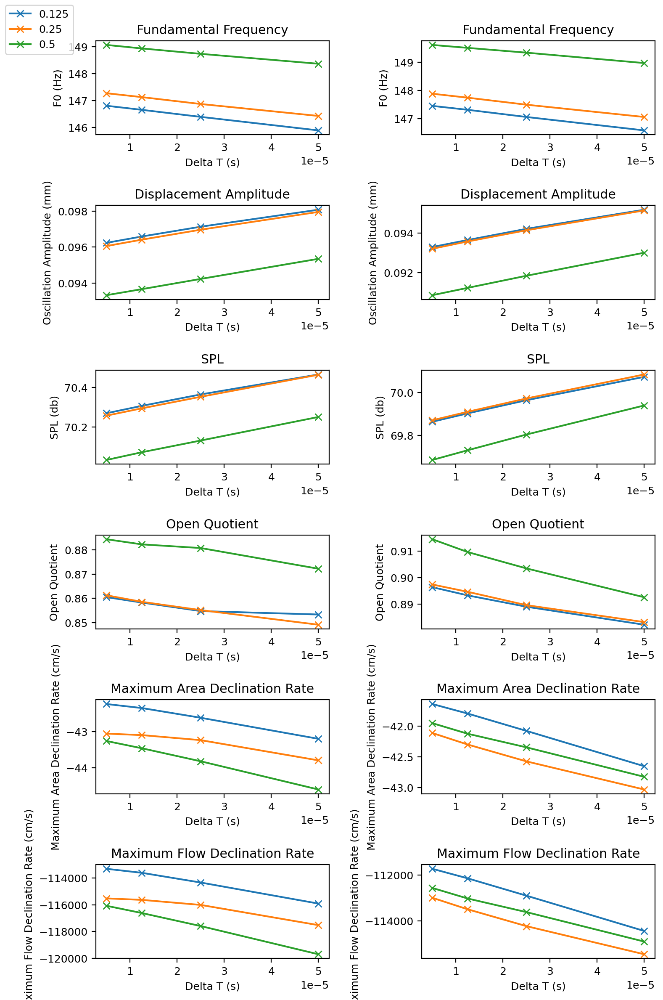

In [12]:
## Plot F0, Amplitude, SPL and OQ for all cases
fig, axs = plt.subplots(6, 2, sharex=False, sharey=False, figsize=(8, 12))

for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        # # Create total plot, dimensions are length, width
        axs[0, iS].set_title('Fundamental Frequency')
        axs[0, iS].set_xlabel("Delta T (s)")
        axs[0, iS].set_ylabel("F0 (Hz)")
        axs[0, iS].plot(deltaTs, F0_array[iS, iC, :], marker="x")
            
        axs[1, iS].set_title("Displacement Amplitude")
        axs[1, iS].set_xlabel("Delta T (s)")
        axs[1, iS].set_ylabel("Oscillation Amplitude (mm)")
        axs[1, iS].plot(deltaTs, amp_array[iS, iC, :], marker="x")
        
        axs[2, iS].set_title("SPL")
        axs[2, iS].set_xlabel("Delta T (s)")
        axs[2, iS].set_ylabel("SPL (db)")
        axs[2, iS].plot(deltaTs, SPL_array[iS, iC, :], marker="x")
    
        axs[3, iS].set_title("Open Quotient")
        axs[3, iS].set_xlabel("Delta T (s)")
        axs[3, iS].set_ylabel("Open Quotient")
        axs[3, iS].plot(deltaTs, OQ_array[iS, iC, :], marker="x")
        
        axs[4, iS].set_title("Maximum Area Declination Rate")
        axs[4, iS].set_xlabel("Delta T (s)")
        axs[4, iS].set_ylabel("Maximum Area Declination Rate (cm/s)")
        axs[4, iS].plot(deltaTs, MADR_array[iS, iC, :], marker="x")

        axs[5, iS].set_title("Maximum Flow Declination Rate")
        axs[5, iS].set_xlabel("Delta T (s)")
        axs[5, iS].set_ylabel("Maximum Flow Declination Rate (cm/s)")
        axs[5, iS].plot(deltaTs, MFDR_array[iS, iC, :], marker="x")
        
fig.legend(CLScales, loc='upper left')
fig.tight_layout(pad=2)
if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/SpeechQuantities.{FIG_EXT}')

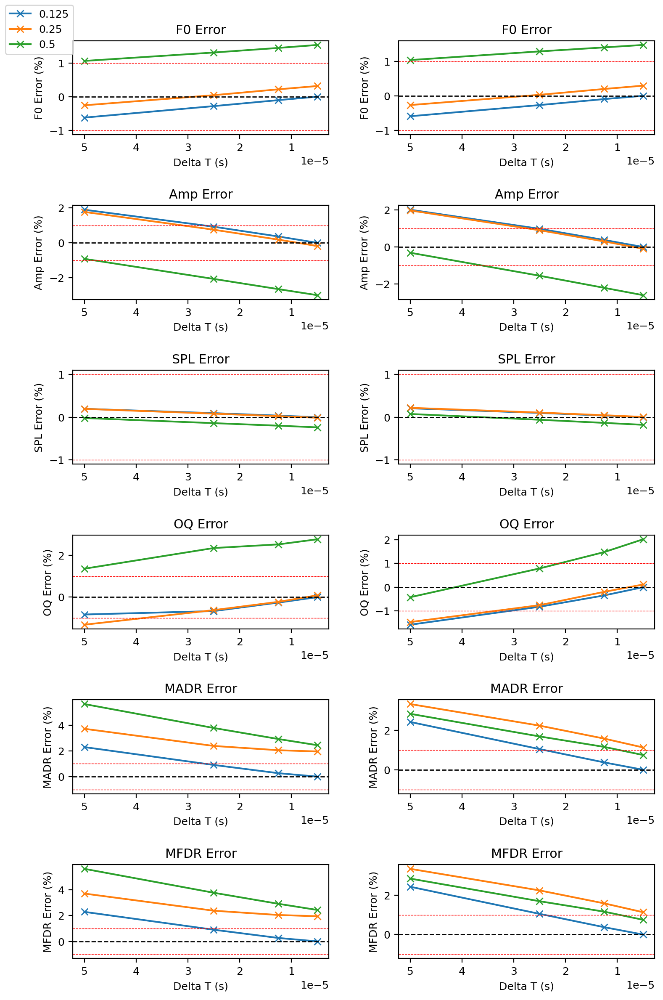

In [14]:
# Define arrays for errors in values
F0_error = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
amp_error = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
SPL_error = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
OQ_error = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
MADR_error = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
MFDR_error = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')

for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        for iT in range(0, len(deltaTs)):
            F0_error[iS, iC, iT] = (F0_array[iS, iC, iT] - F0_array[iS, 0, 0])/F0_array[iS, 0, 0]*100
            amp_error[iS, iC, iT] = (amp_array[iS, iC, iT] - amp_array[iS, 0, 0])/amp_array[iS, 0, 0]*100
            # SPL_error[iS, iC, iT] = (SPL_array[iS, iC, iT] - SPL_array[iS, 0, 0])/SPL_array[iS, 0, 0]*100 # Old percentage based SPL error
            SPL_error[iS, iC, iT] = SPL_array[iS, iC, iT] - SPL_array[iS, 0, 0] # New flat diff SPL error (comparing changes in dB)
            OQ_error[iS, iC, iT] = (OQ_array[iS, iC, iT] - OQ_array[iS, 0, 0])/OQ_array[iS, 0, 0]*100
            MADR_error[iS, iC, iT] = (MADR_array[iS, iC, iT] - MADR_array[iS, 0, 0])/MADR_array[iS, 0, 0]*100
            MFDR_error[iS, iC, iT] = (MFDR_array[iS, iC, iT] - MFDR_array[iS, 0, 0])/MFDR_array[iS, 0, 0]*100

fig, axs = plt.subplots(6, 2, sharex=False, sharey=False, figsize=(8, 12))

for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        # # Create total plot, dimensions are length, width
        axs[0, iS].set_title('F0 Error')
        axs[0, iS].set_xlabel("Delta T (s)")
        axs[0, iS].set_ylabel("F0 Error (%)")
        axs[0, iS].plot(deltaTs, F0_error[iS, iC, :], marker="x")
        axs[0, iS].xaxis.set_inverted(True)
        
        axs[1, iS].set_title("Amp Error")
        axs[1, iS].set_xlabel("Delta T (s)")
        axs[1, iS].set_ylabel("Amp Error (%)")
        axs[1, iS].plot(deltaTs, amp_error[iS, iC, :], marker="x")
        axs[1, iS].xaxis.set_inverted(True)
        
        axs[2, iS].set_title("SPL Error")
        axs[2, iS].set_xlabel("Delta T (s)")
        axs[2, iS].set_ylabel("SPL Error (%)")
        axs[2, iS].plot(deltaTs, SPL_error[iS, iC, :], marker="x")
        axs[2, iS].xaxis.set_inverted(True)
        
        axs[3, iS].set_title("OQ Error")
        axs[3, iS].set_xlabel("Delta T (s)")
        axs[3, iS].set_ylabel("OQ Error (%)")
        axs[3, iS].plot(deltaTs, OQ_error[iS, iC, :], marker="x")
        axs[3, iS].xaxis.set_inverted(True)
        
        axs[4, iS].set_title("MADR Error")
        axs[4, iS].set_xlabel("Delta T (s)")
        axs[4, iS].set_ylabel("MADR Error (%)")
        axs[4, iS].plot(deltaTs, MADR_error[iS, iC, :], marker="x")
        axs[4, iS].xaxis.set_inverted(True)
        
        axs[5, iS].set_title("MFDR Error")
        axs[5, iS].set_xlabel("Delta T (s)")
        axs[5, iS].set_ylabel("MFDR Error (%)")
        axs[5, iS].plot(deltaTs, MFDR_error[iS, iC, :], marker="x")
        axs[5, iS].xaxis.set_inverted(True)
        
fig.legend(CLScales, loc='upper left')
fig.tight_layout(pad=2)

for iS in range(0, len(ScarDias)):
    for i in range(0, 6):
        axs[i, iS].axhline(y=0, color='k', linestyle='--', linewidth=1)
        axs[i, iS].axhline(y=1, color='r', linestyle='--', linewidth=0.5)
        axs[i, iS].axhline(y=-1, color='r', linestyle='--', linewidth=0.5)

if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/SpeechQuantitiesChange.{FIG_EXT}')

## VM Stresses

In [59]:
## Parsing VM Data
vm_vertex = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
dvm = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
dvm_cover = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
dvm_body = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
dvm_scar = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]

dvm_max = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]

# New variables, getting absolute values so percentage error can be calculated
vm = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
vm_cover = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
vm_body = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
vm_scar = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]


for iS in range(0, len(ScarDias)):
    # VM of most refined case for each scar geometry (min CLScale and dt)
    minCL = CLScales.index(min(CLScales))
    minT = deltaTs.index(min(deltaTs))

    vm_ref = np.array([load_measures_np(SIGNALS, f'field.tavg_vm', {'clscale': CLScales[minCL], 'dt': deltaTs[minT], 'SD': ScarDias[iS]})])[0]/10/1e3

    # Getting reference refined mesh for each geometry
    fspace_cg1_ref = dfn.FunctionSpace(MESH[iS][minCL][minT], 'CG', 1)#forms['fspace.scalar']
    fspace_dg0_ref = dfn.FunctionSpace(MESH[iS][minCL][minT], 'DG', 0)
    z_cg1_ref = dfn.Function(fspace_cg1_ref)
    z_dg0_ref = dfn.Function(fspace_dg0_ref)
    z_dg0_ref.set_allow_extrapolation(1)
    
    z_dg0_ref.vector()[:] = vm_ref
    # Need to project dg0 values of VM onto CG1 mesh to allow for comparison, otherwise mismatching nodes and error
    vm_proj_ref = dfn.project(z_dg0_ref, fspace_cg1_ref, function=z_cg1_ref).vector()[VERT_TO_SDOF[iS][minCL][minT]]

    # TODO trying to obtain the average VM stresses for each region separately, but having issues getting mesh subsections
    # Can just process submesh values anyways and just filter out all 0 values afterwards?
    vm_ref_c = [0 if i not in CELLS_COVER[iS][minCL][minT] else vm_ref[i] for i in range(0, len(CELLS[iS][minCL][minT]))]
    z_dg0_ref.vector()[:] = vm_ref_c
    vm_proj_ref_c = dfn.project(z_dg0_ref, fspace_cg1_ref, function=z_cg1_ref).vector()[VERT_TO_SDOF[iS][minCL][minT]]

    vm_ref_b = [0 if i not in CELLS_BODY[iS][minCL][minT] else vm_ref[i] for i in range(0, len(CELLS[iS][minCL][minT]))]
    z_dg0_ref.vector()[:] = vm_ref_b
    vm_proj_ref_b = dfn.project(z_dg0_ref, fspace_cg1_ref, function=z_cg1_ref).vector()[VERT_TO_SDOF[iS][minCL][minT]]
    
    if ScarDias[iS] > 0:
        vm_ref_s = [0 if i not in CELLS_SCAR[iS][minCL][minT] else vm_ref[i] for i in range(0, len(CELLS[iS][minCL][minT]))]
        z_dg0_ref.vector()[:] = vm_ref_s
        vm_proj_ref_s = dfn.project(z_dg0_ref, fspace_cg1_ref, function=z_cg1_ref).vector()[VERT_TO_SDOF[iS][minCL][minT]]

    
    
    for iC in range(0, len(CLScales)):
        for iT in range(0, len(deltaTs)):

            # data_vm_raw = load_measures_np(SIGNALS, f'field.tavg_vm', {'clscale': CLScales[iC], 'dt': deltaTs[iT], 'SD': ScarDias[iS]})
            # data_vm = np.array(data_vm_raw)[0]/10/1e3
            data_vm = np.array([load_measures_np(SIGNALS, f'field.tavg_vm', {'clscale': CLScales[iC], 'dt': deltaTs[iT], 'SD': ScarDias[iS]})])[0]/10/1e3
                
            fspace_cg1 = dfn.FunctionSpace(MESH[iS][iC][iT], 'CG', 1)#forms['fspace.scalar']
            fspace_dg0 = dfn.FunctionSpace(MESH[iS][iC][iT], 'DG', 0)
            z_cg1 = dfn.Function(fspace_cg1)
            z_dg0 = dfn.Function(fspace_dg0)    
            # Extrapolation is required for coarser meshes
            # Lower resolution meshes missing some area, requiring extrapolation from coarse meshes
            z_dg0.set_allow_extrapolation(1)

            z_dg0.vector()[:] = data_vm
            vm_proj = dfn.project(z_dg0, fspace_cg1_ref, function=z_cg1_ref).vector()[VERT_TO_SDOF[iS][minCL][minT]]
            
            vm_c = [0 if i not in CELLS_COVER[iS][iC][iT] else data_vm[i] for i in range(0, len(CELLS[iS][iC][iT]))]
            z_dg0.vector()[:] = vm_c
            vm_proj_c = dfn.project(z_dg0, fspace_cg1_ref, function=z_cg1_ref).vector()[VERT_TO_SDOF[iS][minCL][minT]]
            
            vm_b = [0 if i not in CELLS_BODY[iS][iC][iT] else data_vm[i] for i in range(0, len(CELLS[iS][iC][iT]))]
            z_dg0.vector()[:] = vm_b
            vm_proj_b = dfn.project(z_dg0, fspace_cg1_ref, function=z_cg1_ref).vector()[VERT_TO_SDOF[iS][minCL][minT]]
            
            if ScarDias[iS] > 0:
                vm_s = [0 if i not in CELLS_SCAR[iS][iC][iT] else data_vm[i] for i in range(0, len(CELLS[iS][iC][iT]))]
                z_dg0.vector()[:] = vm_s
                vm_proj_s = dfn.project(z_dg0, fspace_cg1_ref, function=z_cg1_ref).vector()[VERT_TO_SDOF[iS][minCL][minT]]
                dvm_scar[iS][iC][iT] = sum(abs(vm_proj_s-vm_proj_ref_s))/len(CELLS_SCAR[iS][iC][iT])
            
            dvm[iS][iC][iT] = sum(abs(vm_proj-vm_proj_ref))/len(vm_proj)
            dvm_max[iS][iC][iT] = max(abs(vm_proj-vm_proj_ref))

            dvm_cover[iS][iC][iT] = sum(abs(vm_proj_c-vm_proj_ref_c))/len(CELLS_COVER[iS][iC][iT])
            dvm_body[iS][iC][iT] = sum(abs(vm_proj_b-vm_proj_ref_b))/len(CELLS_BODY[iS][iC][iT])
            
            
            vm[iS][iC][iT] = vm_proj
            vm_cover[iS][iC][iT] = vm_proj_c
            vm_body[iS][iC][iT] = vm_proj_b
            if ScarDias[iS] > 0:
                vm_scar[iS][iC][iT] = vm_proj_s
            

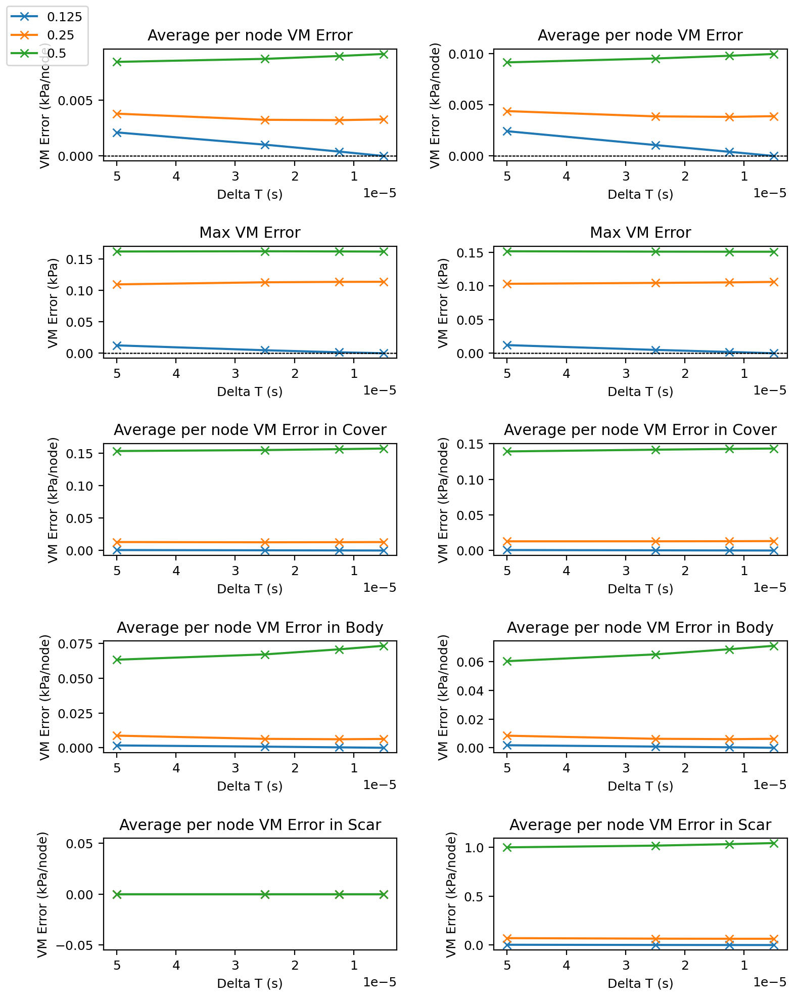

In [58]:
# Define arrays for errors in values
vm_error = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')

# for iS in range(0, len(ScarDias)):
#     for iC in range(0, len(CLScales)):
#         for iT in range(0, len(deltaTs)):
            # vm_error[iS, iC, iT] = (dvm[iS][iC][iT] - dvm[iS][0][0])/dvm[iS][0][0]*100
            
fig, axs = plt.subplots(5, 2, sharex=False, sharey=False, figsize=(8, 10))

for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        # # Create total plot, dimensions are length, width
        axs[0, iS].set_title('Average per node VM Error')
        axs[0, iS].set_xlabel("Delta T (s)")
        axs[0, iS].set_ylabel("VM Error (kPa/node)")
        axs[0, iS].plot(deltaTs, dvm[iS][iC][:], marker="x")
        axs[0, iS].xaxis.set_inverted(True)

        axs[1, iS].set_title('Average per node VM Error in Cover')
        axs[1, iS].set_xlabel("Delta T (s)")
        axs[1, iS].set_ylabel("VM Error (kPa/node)")
        axs[1, iS].plot(deltaTs, dvm_cover[iS][iC][:], marker="x")
        axs[1, iS].xaxis.set_inverted(True)
        
        axs[2, iS].set_title('Average per node VM Error in Body')
        axs[2, iS].set_xlabel("Delta T (s)")
        axs[2, iS].set_ylabel("VM Error (kPa/node)")
        axs[2, iS].plot(deltaTs, dvm_body[iS][iC][:], marker="x")
        axs[2, iS].xaxis.set_inverted(True)

        axs[3, iS].set_title('Average per node VM Error in Scar')
        axs[3, iS].set_xlabel("Delta T (s)")
        axs[3, iS].set_ylabel("VM Error (kPa/node)")
        axs[3, iS].plot(deltaTs, dvm_scar[iS][iC][:], marker="x")
        axs[3, iS].xaxis.set_inverted(True)

        axs[4, iS].set_title('Max VM Error')
        axs[4, iS].set_xlabel("Delta T (s)")
        axs[4, iS].set_ylabel("VM Error (kPa)")
        axs[4, iS].plot(deltaTs, dvm_max[iS][iC][:], marker="x")
        axs[4, iS].xaxis.set_inverted(True)
fig.legend(CLScales, loc='upper left')
fig.tight_layout(pad=2)

for iS in range(0, len(ScarDias)):
    for i in range(0, 5):
        axs[i, iS].axhline(y=0, color='k', linestyle='--', linewidth=1)
        axs[i, iS].axhline(y=1, color='r', linestyle='--', linewidth=0.5)
        axs[i, iS].axhline(y=-1, color='r', linestyle='--', linewidth=0.5)

if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/SpeechQuantitiesChange.{FIG_EXT}')

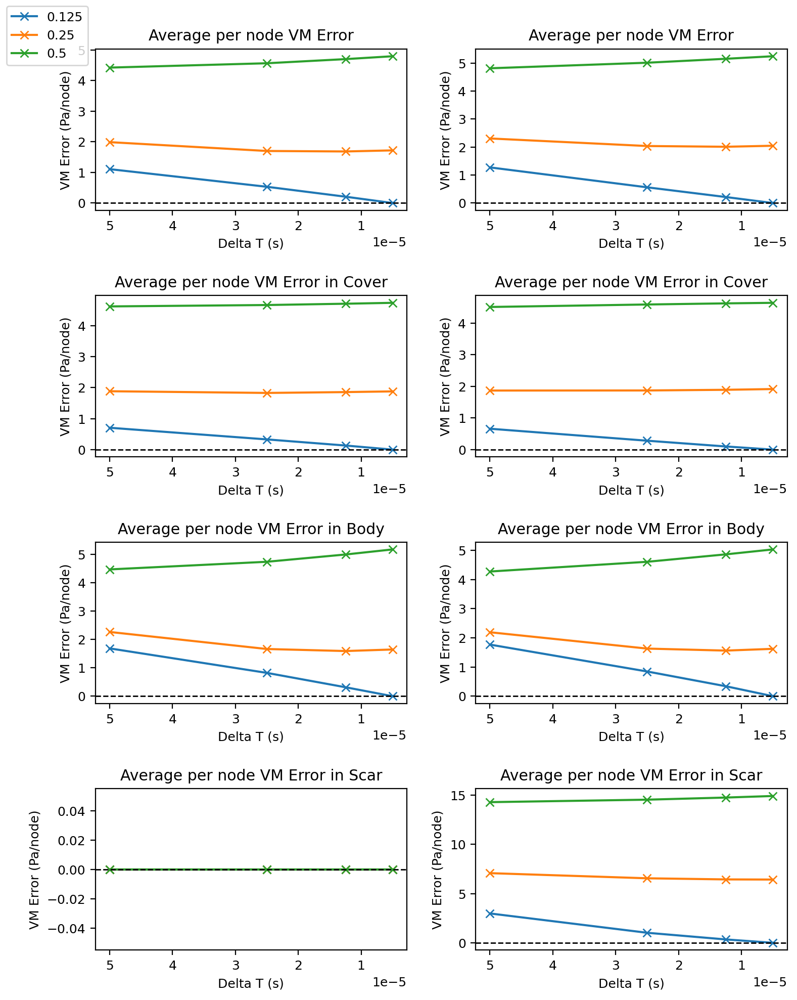

In [82]:
# Define arrays for errors in values
# vm_error = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
# vm_error_c = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
# vm_error_b = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
# vm_error_s = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
max_vm = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
max_vm_c = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
max_vm_b = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
max_vm_s = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')

for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        for iT in range(0, len(deltaTs)):
            dvm[iS][iC][iT] = sum((abs(vm[iS][iC][iT] - vm[iS][0][0])))/len(CELLS[iS][0][0])*1e3
            dvm_cover[iS][iC][iT] = sum((abs(vm_cover[iS][iC][iT] - vm_cover[iS][0][0])))/len(CELLS_COVER[iS][0][0])*1e3
            dvm_body[iS][iC][iT] = sum((abs(vm_body[iS][iC][iT] - vm_body[iS][0][0])))/len(CELLS_BODY[iS][0][0])*1e3

            max_vm[iS][iC][iT] = max(abs(vm[iS][iC][iT] - vm[iS][0][0]))
            max_vm_c[iS][iC][iT] = max(abs(vm_cover[iS][iC][iT] - vm_cover[iS][0][0]))
            max_vm_b[iS][iC][iT] = max(abs(vm_body[iS][iC][iT] - vm_body[iS][0][0]))
            
            
            if ScarDias[iS] > 0:
                dvm_scar[iS][iC][iT] = sum((abs(vm_scar[iS][iC][iT] - vm_scar[iS][0][0])))/len(CELLS_SCAR[iS][0][0])*1e3
                max_vm_s[iS][iC][iT] = max(abs(vm_scar[iS][iC][iT] - vm_scar[iS][0][0]))
            else:
                # avoid scary looking graphs caused by fake data for BC case
                dvm_scar[iS][iC][iT] = 0
                max_vm_s[iS][iC][iT] = 0
fig, axs = plt.subplots(4, 2, sharex=False, sharey=False, figsize=(8, 10))

for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        # # Create total plot, dimensions are length, width
        axs[0, iS].set_title('Average per node VM Error')
        axs[0, iS].set_xlabel("Delta T (s)")
        axs[0, iS].set_ylabel("VM Error (Pa/node)")
        axs[0, iS].plot(deltaTs, dvm[iS][iC][:], marker="x")
        axs[0, iS].xaxis.set_inverted(True)

        axs[1, iS].set_title('Average per node VM Error in Cover')
        axs[1, iS].set_xlabel("Delta T (s)")
        axs[1, iS].set_ylabel("VM Error (Pa/node)")
        axs[1, iS].plot(deltaTs, dvm_cover[iS][iC][:], marker="x")
        axs[1, iS].xaxis.set_inverted(True)
        
        axs[2, iS].set_title('Average per node VM Error in Body')
        axs[2, iS].set_xlabel("Delta T (s)")
        axs[2, iS].set_ylabel("VM Error (Pa/node)")
        axs[2, iS].plot(deltaTs, dvm_body[iS][iC][:], marker="x")
        axs[2, iS].xaxis.set_inverted(True)

        axs[3, iS].set_title('Average per node VM Error in Scar')
        axs[3, iS].set_xlabel("Delta T (s)")
        axs[3, iS].set_ylabel("VM Error (Pa/node)")
        axs[3, iS].plot(deltaTs, dvm_scar[iS][iC][:], marker="x")
        axs[3, iS].xaxis.set_inverted(True)

        # axs[4, iS].set_title('Max VM Error')
        # axs[4, iS].set_xlabel("Delta T (s)")
        # axs[4, iS].set_ylabel("VM Error (kPa)")
        # axs[4, iS].plot(deltaTs, dvm_max[iS][iC][:], marker="x")
        # axs[4, iS].xaxis.set_inverted(True)
fig.legend(CLScales, loc='upper left')
fig.tight_layout(pad=2)

for iS in range(0, len(ScarDias)):
    for i in range(0, 4):
        axs[i, iS].axhline(y=0, color='k', linestyle='--', linewidth=1)
        # axs[i, iS].axhline(y=1, color='r', linestyle='--', linewidth=0.5)
        # axs[i, iS].axhline(y=-1, color='r', linestyle='--', linewidth=0.5)

if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/SpeechQuantitiesChange.{FIG_EXT}')

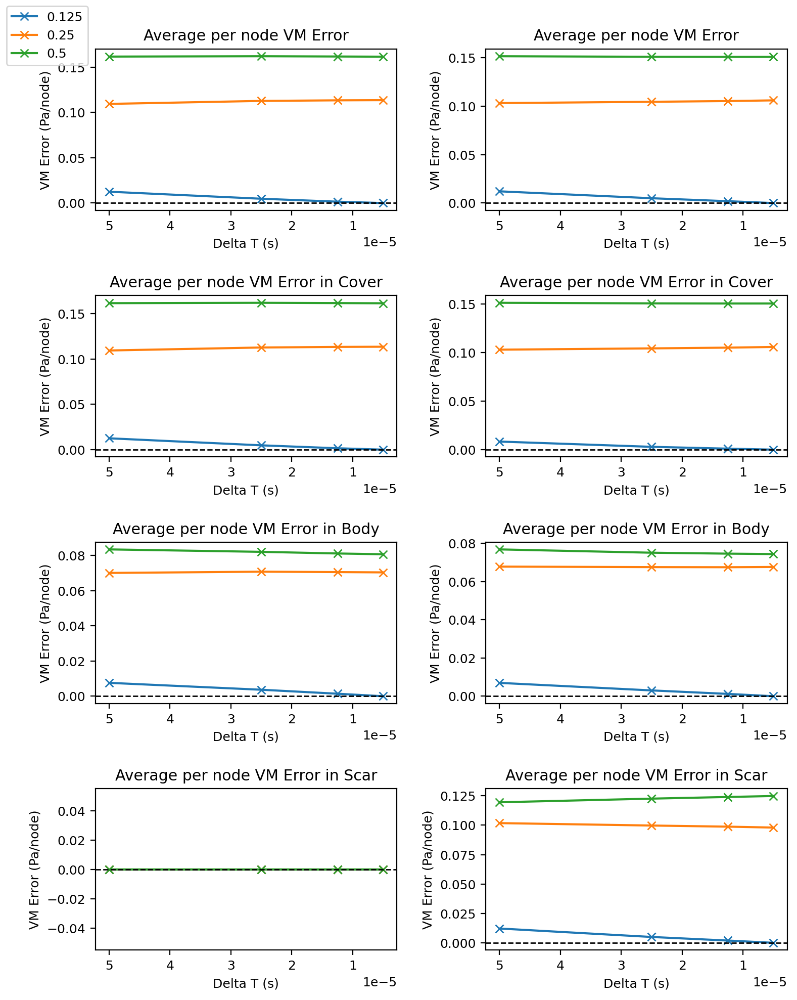

In [84]:
# Max VM error values
fig, axs = plt.subplots(4, 2, sharex=False, sharey=False, figsize=(8, 10))
for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        # # Create total plot, dimensions are length, width
        axs[0, iS].set_title('Max VM Error')
        axs[0, iS].set_xlabel("Delta T (s)")
        axs[0, iS].set_ylabel("VM Error kPa")
        axs[0, iS].plot(deltaTs, max_vm[iS][iC][:], marker="x")
        axs[0, iS].xaxis.set_inverted(True)

        axs[1, iS].set_title('Max VM Error in Cover')
        axs[1, iS].set_xlabel("Delta T (s)")
        axs[1, iS].set_ylabel("VM Error kPa")
        axs[1, iS].plot(deltaTs, max_vm_c[iS][iC][:], marker="x")
        axs[1, iS].xaxis.set_inverted(True)
        
        axs[2, iS].set_title('Max VM Error in Body')
        axs[2, iS].set_xlabel("Delta T (s)")
        axs[2, iS].set_ylabel("VM Error kPa")
        axs[2, iS].plot(deltaTs, max_vm_b[iS][iC][:], marker="x")
        axs[2, iS].xaxis.set_inverted(True)

        axs[3, iS].set_title('Max VM Error in Scar')
        axs[3, iS].set_xlabel("Delta T (s)")
        axs[3, iS].set_ylabel("VM Error kPa")
        axs[3, iS].plot(deltaTs, max_vm_s[iS][iC][:], marker="x")
        axs[3, iS].xaxis.set_inverted(True)

fig.legend(CLScales, loc='upper left')
fig.tight_layout(pad=2)

for iS in range(0, len(ScarDias)):
    for i in range(0, 4):
        axs[i, iS].axhline(y=0, color='k', linestyle='--', linewidth=1)
        # axs[i, iS].axhline(y=1, color='r', linestyle='--', linewidth=0.5)
        # axs[i, iS].axhline(y=-1, color='r', linestyle='--', linewidth=0.5)

if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/SpeechQuantitiesChange.{FIG_EXT}')

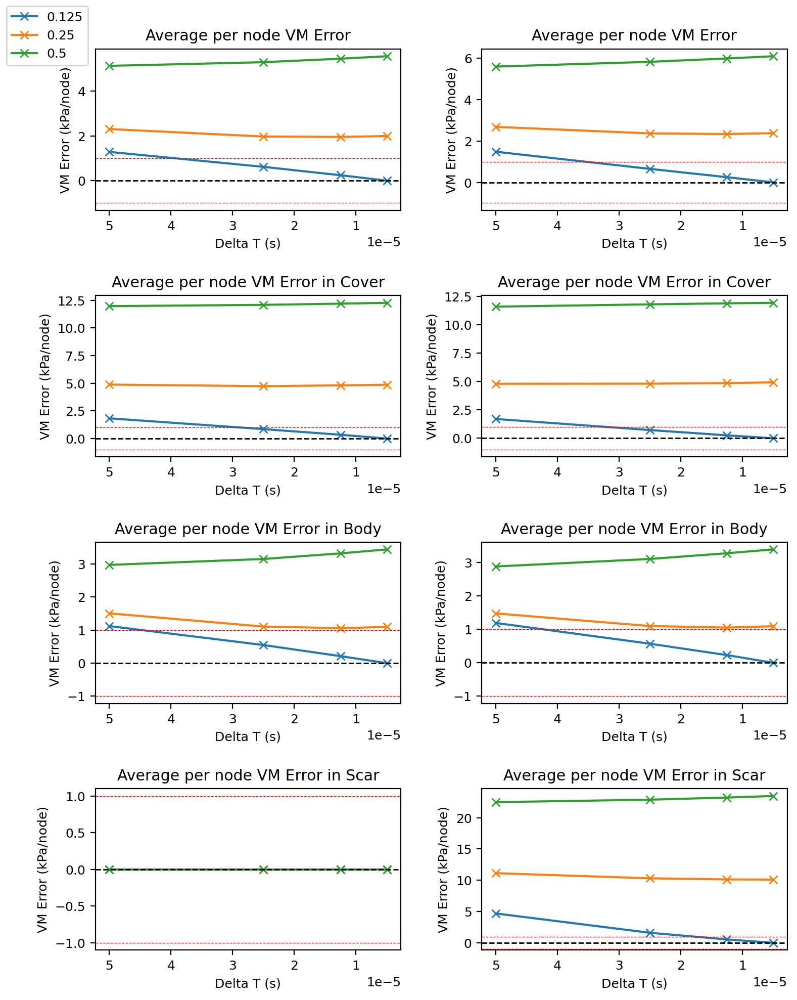

In [73]:
# Define arrays for errors in values
vm_error = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
vm_error_c = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
vm_error_b = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')
vm_error_s = np.empty((len(ScarDias), len(CLScales), len(deltaTs)), dtype='float64')

for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        for iT in range(0, len(deltaTs)):
            vm_error[iS][iC][iT] = sum((abs(vm[iS][iC][iT] - vm[iS][0][0])))/sum(vm[iS][0][0])*100
            vm_error_c[iS][iC][iT] = sum((abs(vm_cover[iS][iC][iT] - vm_cover[iS][0][0])))/sum(vm_cover[iS][0][0])*100
            vm_error_b[iS][iC][iT] = sum((abs(vm_body[iS][iC][iT] - vm_body[iS][0][0])))/sum(vm_body[iS][0][0])*100
            if ScarDias[iS] > 0:
                vm_error_s[iS][iC][iT] = sum((abs(vm_scar[iS][iC][iT] - vm_scar[iS][0][0])))/sum(vm_scar[iS][0][0])*100
            else:
                # avoid scary looking graphs caused by fake data for BC case
                vm_error_s[iS][iC][iT] = 0
fig, axs = plt.subplots(4, 2, sharex=False, sharey=False, figsize=(8, 10))

for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        # # Create total plot, dimensions are length, width
        axs[0, iS].set_title('Total VM Error')
        axs[0, iS].set_xlabel("Delta T (s)")
        axs[0, iS].set_ylabel("VM Error (%)")
        axs[0, iS].plot(deltaTs, vm_error[iS][iC][:], marker="x")
        axs[0, iS].xaxis.set_inverted(True)

        axs[1, iS].set_title('VM Error in Cover Region')
        axs[1, iS].set_xlabel("Delta T (s)")
        axs[1, iS].set_ylabel("VM Error (%)")
        axs[1, iS].plot(deltaTs, vm_error_c[iS][iC][:], marker="x")
        axs[1, iS].xaxis.set_inverted(True)
        
        axs[2, iS].set_title('VM Error in Body Region')
        axs[2, iS].set_xlabel("Delta T (s)")
        axs[2, iS].set_ylabel("VM Error (%)")
        axs[2, iS].plot(deltaTs, vm_error_b[iS][iC][:], marker="x")
        axs[2, iS].xaxis.set_inverted(True)

        axs[3, iS].set_title('VM Error in Scar Region')
        axs[3, iS].set_xlabel("Delta T (s)")
        axs[3, iS].set_ylabel("VM Error (%)")
        axs[3, iS].plot(deltaTs, vm_error_s[iS][iC][:], marker="x")
        axs[3, iS].xaxis.set_inverted(True)

        # axs[4, iS].set_title('Max VM Error')
        # axs[4, iS].set_xlabel("Delta T (s)")
        # axs[4, iS].set_ylabel("VM Error (kPa)")
        # axs[4, iS].plot(deltaTs, dvm_max[iS][iC][:], marker="x")
        # axs[4, iS].xaxis.set_inverted(True)
fig.legend(CLScales, loc='upper left')
fig.tight_layout(pad=2)

for iS in range(0, len(ScarDias)):
    for i in range(0, 4):
        axs[i, iS].axhline(y=0, color='k', linestyle='--', linewidth=1)
        axs[i, iS].axhline(y=1, color='r', linestyle='--', linewidth=0.5)
        axs[i, iS].axhline(y=-1, color='r', linestyle='--', linewidth=0.5)

if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/SpeechQuantitiesChange.{FIG_EXT}')

## Contact Stresses

In [31]:
residual = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
mesh = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
facet_function = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
facet_data = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
dofmap = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]

# Coordinates of all facets along the surface, which is needed for the 2D plot
facet_coords = [[[[] for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
facet_cell_neighbour_dofs = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]

# Surface nodes normalized to s space
facet_s = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]

# Contact quotient
dat_cq = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]

# Contact pressure field
dat = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]

for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        for iT in range(0, len(deltaTs)):
            ## Compute the 's' coordinate for the DG0 contact pressure
            residual[iS][iC][iT] = MODEL[iS][iC][iT].solid.residual
            mesh[iS][iC][iT] = residual[iS][iC][iT].mesh()
    
            # facets are 1d elements, not the same as nodes. Will need some other method to link the nodes and facets together
            # https://olddocs.fenicsproject.org/dolfin/2016.1.0/python/programmers-reference/cpp/mesh/Vertex.html
            # https://olddocs.fenicsproject.org/dolfin/2016.1.0/python/programmers-reference/cpp/mesh/Facet.html
            
            facet_function[iS][iC][iT] = residual[iS][iC][iT].mesh_function('facet')
            facet_data[iS][iC][iT] = residual[iS][iC][iT].mesh_function_label_to_value('facet')
            dofmap[iS][iC][iT] = residual[iS][iC][iT].form['coeff.prop.eta'].function_space().dofmap()
    
            # Find facets along the traction surface and associated DG0 dofs
            facet_cell_neighbour_idxs = []
            for facet in dfn.facets(mesh[iS][iC][iT]):
            # get all facet ids and check if it is along the pressure surface
                facet_idx = facet.index()
                if facet_function[iS][iC][iT][facet_idx] == facet_data[iS][iC][iT]['pressure']:
                    facet_coord = facet.midpoint().array()[:2]
                    # Save the new surface coords and id to separate numpy lists (keep separate for sorting soon)
                    facet_coords[iS][iC][iT].append(facet_coord)
                    
                    cell_neighbour_idx = facet.entities(2)
                    assert len(cell_neighbour_idx) == 1
                    cell_neighbour_idx = cell_neighbour_idx[0]
                    facet_cell_neighbour_idxs.append(cell_neighbour_idx)
    
            facet_coords[iS][iC][iT] = np.array(facet_coords[iS][iC][iT])
            facet_cell_neighbour_idxs = np.array(facet_cell_neighbour_idxs)
            facet_cell_neighbour_dofs[iS][iC][iT] = np.array(dofmap[iS][iC][iT].entity_dofs(mesh[iS][iC][iT], 2, facet_cell_neighbour_idxs))
            
            # Sort the DG0 dofs in streamwise increasing order
            from femvf.meshutils import sort_vertices_by_nearest_neighbours
            
            idx_sort = sort_vertices_by_nearest_neighbours(facet_coords[iS][iC][iT], np.array([0,0]))
            facet_coords[iS][iC][iT] = facet_coords[iS][iC][iT][idx_sort]
            
            facet_cell_neighbour_dofs[iS][iC][iT] = facet_cell_neighbour_dofs[iS][iC][iT][idx_sort]
            _facet_coords = np.concatenate([facet_coords[iS][iC][iT], np.array([[0, 0]])], axis=0)
            ds = np.linalg.norm(_facet_coords[1:]-_facet_coords[:-1], axis=-1)
    
            # Surface facets converted to a range from -1 to 1, with 0 being the separation point(?)
            facet_s[iS][iC][iT] = np.cumsum(ds) - 1
    
            _dat_pcfield = load_measures_np(SIGNALS, 'field.tavg_pc', {'clscale': MeshNames[iC], 'SD': ScarDias[iS]})
            _dat_pc = load_measures_np(SIGNALS, 'time.spatial_stats_con_p', {'clscale': MeshNames[iC], 'SD': ScarDias[iS]})
            _dat_pa = load_measures_np(SIGNALS, 'time.spatial_stats_con_a', {'clscale': MeshNames[iC], 'SD': ScarDias[iS]})
    
            # Obtain contact quotient (amount of time with contact, defined by where the contact pressure is non-zero)
            # This also accounts for the initial transient state, but is assumed to be negligible with sufficiently long simulation time
            dat_cq[iS][iC][iT] = len(_dat_pa.nonzero())/len(_dat_pa)
            
            # Load the contact pressure field and account for averaging over contact times only
            # Convert the unit to kpa
            # If multiplying by `1/cq`, the contact pressure is averaged over contact only
            dat[iS][iC][iT] = _dat_pcfield/10/1e3 * 1/dat_cq[iS][iC][iT]

AttributeError: 'list' object has no attribute 'solid'

In [ ]:
# Preliminary contact pressure data (max, average and contact area)
m_pc = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
dm_pc = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
avg_pc = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
davg_pc = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
area_pc = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]
darea_pc = [[[0 for i in range(len(deltaTs))] for j in range(len(CLScales))] for k in range(len(ScarDias))]

fig, axs = plt.subplots(6, 2, sharex=False, sharey=False, figsize=(8, 6))


for iS in range(0, len(ScarDias)):
    for iC in range(0, len(CLScales)):
        for iT in range(0, len(deltaTs)):

            # Convert to kPa
            pc = dat[iS][iC][iT][facet_cell_neighbour_dofs[iS][iC][iT]]/1e3
            m_pc[iS][iC][iT] = max(pc)
            dm_pc[iS][iC][iT] = (m_pc[iS][iC][iT]-m_pc[0][0][0])/m_pc[0][0][0]*100
    
            # Use trapezoidal rule to obtain average force due to varying grid spacing along surface
            total_pc = np.trapezoid(pc, facet_s[iS][iC][iT])
            # Find the glottal contact distance based on the min and max values where glottal force is found
            # not sure why facet_s[iM][iS] is technically a 2D array thats why taking min and max twice
            ds = (facet_s[iS][iC][iT][max(max(np.nonzero(pc)))]-facet_s[iS][iC][iT][min(min(np.nonzero(pc)))])
            area_pc[iS][iC][iT] = ds
            avg_pc[iS][iC][iT] = total_pc/area_pc[iS][iC][iT]
            davg_pc[iS][iC][iT] = (avg_pc[iS][iC][iT]-avg_pc[0][0][0])/avg_pc[0][0][0]*100
    
            darea_pc[iS][iC][iT] = (area_pc[iS][iC][iT]-area_pc[0][0][0])/area_pc[0][0][0]*100

        # Plotting values
        axs[0, iS].set_title('Max Contact Pressure')
        axs[0, iS].set_xlabel("Scar Diameter (cm)")
        axs[0, iS].set_ylabel("Max Contact Pressure (kPa)")
        axs[0, iS].plot(ScarDias, m_pc[iS][iC], marker="x")
    
        axs[1, iS].set_title('Percent Change in Max Contact Pressure')
        axs[1, iS].set_xlabel("Scar Diameter (cm)")
        axs[1, iS].set_ylabel("Percent Change in max CP")
        axs[1, iS].plot(ScarDias, dm_pc[iS][iC], marker="x")
    
        axs[2, iS].set_title('Contact Pressure Area')
        axs[2, iS].set_xlabel("Scar Diameter (cm)")
        axs[2, iS].set_ylabel("Contact Pressure Area (cm)")
        axs[2, iS].plot(ScarDias, area_pc[iS][iC], marker="x")
    
        axs[3, iS].set_title('Percent Change in Contact Pressure Area')
        axs[3, iS].set_xlabel("Scar Diameter (cm)")
        axs[3, iS].set_ylabel("Percent Change CP Area")
        axs[3, iS].plot(ScarDias, darea_pc[iS][iC], marker="x")
        
        axs[4, iS].set_title('Average Contact Pressure')
        axs[4, iS].set_xlabel("Scar Diameter (cm)")
        axs[4, iS].set_ylabel("Average Contact Pressure (kPa)")
        axs[4, iS].plot(ScarDias, avg_pc[iS][iC], marker="x")
    
        axs[5, iS].set_title('Percent Change in Average Contact Pressure')
        axs[5, iS].set_xlabel("Scar Diameter (cm)")
        axs[5, iS].set_ylabel("Percent Change in avg CP")
        axs[5, iS].plot(ScarDias, davg_pc[iS][iC], marker="x")

fig.legend(MeshNames, loc='lower right')
fig.tight_layout(pad=2)
if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}/ContactPressureStats.{FIG_EXT}')

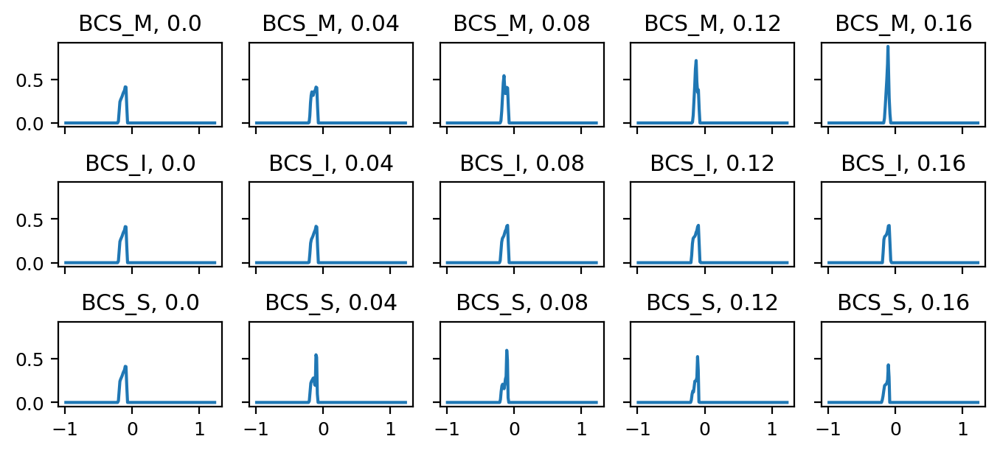

In [15]:
## Plot contact surface pressure profiles (line plot over 's' coordinate)
if FIG_TYPE == 'manuscript':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias), figsize=(FIG_LX_WIDE, 8*CM), sharex=True, sharey=True)
elif FIG_TYPE == 'presentation':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias), figsize=(FIG_LX_WIDE, FIG_LY), sharex=True, sharey=True)

# iC = index_Mesh, iS = index_Scar
for iC in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):
        # Convert to kPa
        pc_medial = dat[iC][iS][facet_cell_neighbour_dofs[iC][iS]]/1e3
        axs[iC][iS].plot(facet_s[iC][iS], pc_medial)
        axs[iC, iS].set_title(MeshNames[iC] + ", " + str(ScarDias[iS]))
        

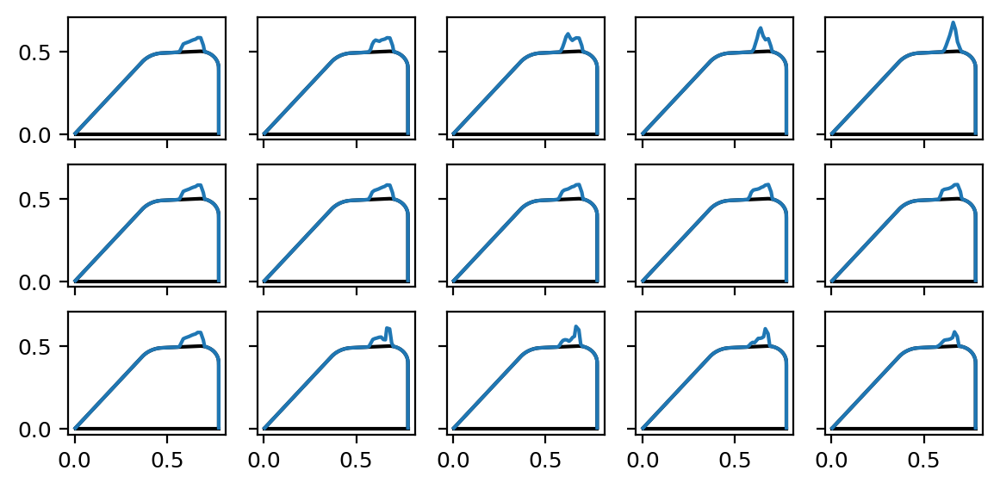

In [17]:
## Plot contact surface pressure profiles (spatial/fancy plot)
if FIG_TYPE == 'manuscript':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias), figsize=(FIG_LX_WIDE, 8*CM), sharex=True, sharey=True)
elif FIG_TYPE == 'presentation':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias), figsize=(FIG_LX_WIDE, FIG_LY), sharex=True, sharey=True)

# Define grid spacing
gs = mpl.gridspec.GridSpec(2, len(MeshNames), height_ratios=[0.1, 1], hspace=0.05)

# iC = index_Mesh, iS = index_Scar
for iC in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):   
        xy_med = facet_coords[iC][iS]
        nn_med = normal(xy_med)
        # Plot VF mesh outline
        axs[iC, iS].plot(xy_med[:, 0], xy_med[:, 1], color='k')
        axs[iC, iS].plot(xy_med[[0, -1], 0], [0, 0], color='k')

        pc_medial = dat[iC][iS][facet_cell_neighbour_dofs[iC][iS]]
        
        scale = -0.2e-3
        pc_norm = [[0, 0] for i in range(len(pc_medial))]
        for iPC in range(0, len(pc_medial)):
            pc_norm[iPC][0] = scale*pc_medial[iPC]*nn_med[iPC][0]
            pc_norm[iPC][1] = scale*pc_medial[iPC]*nn_med[iPC][1]
            # print(scale*pc_medial[iPC]*nn_med[iPC, 0])
            # print(scale*pc_medial[iPC]*nn_med[iPC, 1])            
        
        # pc_n = offset_normal(xy_med, scale*pc_medial*nn_med)
        pc_n = offset_normal(xy_med, pc_norm)
        axs[iC, iS].plot(pc_n[:, 0], pc_n[:, 1])

## 2D Stress Fields

TypeError: Invalid shape () for image data

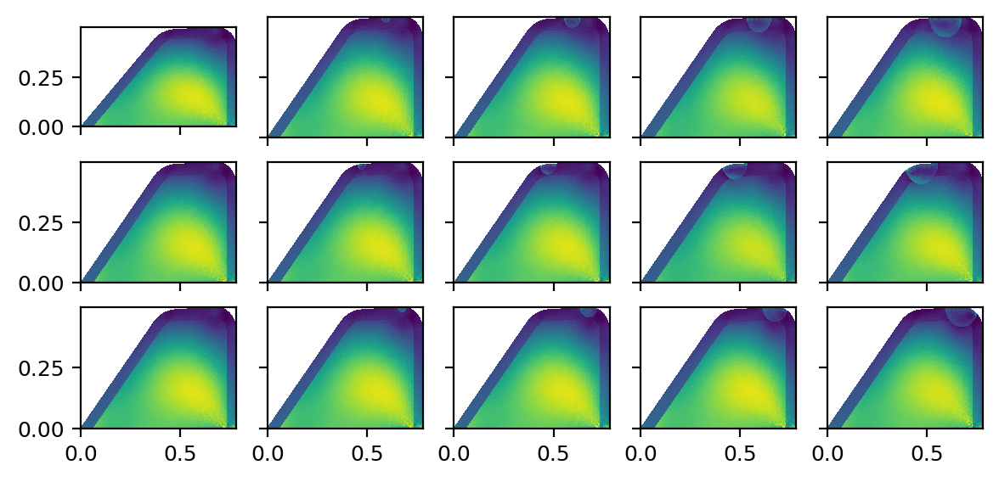

In [20]:
# Obtaining 2D stress field plots for each case
import matplotlib.colorizer as mcolorizer
import matplotlib.colors as mcolors

if FIG_TYPE == 'manuscript':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias), figsize=(FIG_LX_WIDE, 8*CM), sharex=True, sharey=True)
elif FIG_TYPE == 'presentation':
    fig, axs = plt.subplots(len(MeshNames), len(ScarDias), figsize=(FIG_LX_WIDE, FIG_LY), sharex=True, sharey=True)

# Define grid spacing
gs = mpl.gridspec.GridSpec(2, len(MeshNames), height_ratios=[0.1, 1], hspace=0.05)

field_names = [
    'field.tavg_vm',
    'field.tavg_hydrostatic',
    'field.tini_vm',
    'field.tini_hydrostatic'
    # 'field_fp_vm',
    # 'field_fp_hydrostatic',
]

# field_dat = [[{} for i in range(len(MeshNames))] for j in range(len(ScarDias))]
# ys = [[[] for i in range(len(MeshNames))] for j in range(len(ScarDias))]

field_dat = [[{} for i in range(len(ScarDias))] for j in range(len(MeshNames))]
ys = [[[] for i in range(len(ScarDias))] for j in range(len(MeshNames))]

# iC = index_Mesh, iS = index_Scar
for iC in range(0, len(MeshNames)):
    for iS in range(0, len(ScarDias)):
        field_dat[iC][iS] = {
            # Only measurement name is needed for key since geometric parameters are handled by the outer 2D array
            f'{field_name}': load_measures_np(SIGNALS, f'{field_name}', {'MeshName': MeshNames[iC], 'SD': ScarDias[iS]})
            for field_name in field_names
        }
        
        # VERT_TO_VDOF, CELLS are defined early on in notebook when loading model info, dependent on the meshes
        XREF_VERT = XREF[iC][iS][VERT_TO_VDOF[iC][iS]].reshape(-1, 2)
        trian = tri.Triangulation(XREF_VERT[:, 0], XREF_VERT[:, 1], CELLS[iC][iS])

        ys[iC][iS] = np.array([
            # Convert field_dat vals to kPa
            field_dat[iC][iS][f'field.tavg_vm']/10/1e3
        ])

        ys_abs = ys[iC][iS][0]

        # Hardcoding the plot_tripcolor_seq because of issues with working with current axs implementation
        zmin = np.min(ys_abs)
        zmax = np.max(ys_abs)
        kwargs = {'vmin': zmin, 'vmax': zmax, 'edgecolors': 'none'}
        
        fspace_cg1 = dfn.FunctionSpace(MODEL[iC][iS].solid.residual.mesh(), 'CG', 1)#forms['fspace.scalar']
        fspace_dg0 = dfn.FunctionSpace(MODEL[iC][iS].solid.residual.mesh(), 'DG', 0)
        z_cg1 = dfn.Function(fspace_cg1)
        z_dg0 = dfn.Function(fspace_dg0)
    
        ys_abs_flat = ys_abs.reshape(-1, ys_abs.shape[-1])
        artists = axs[iC, iS].tripcolor(trian, ys_abs, **kwargs)
    
        ## Project the dg0 stress to CG1 so you can plot contours
        z_dg0.vector()[:] = ys_abs
        z_vertex = dfn.project(z_dg0, fspace_cg1, function=z_cg1).vector()[VERT_TO_SDOF[iC][iS]]
        # Setting 'Greys' cmap and vmin/vmax appropriately will ensure a specific color for the contour line
        # cmap = plt.get_cmap(name='Greys')
        axs[iC, iS].tricontour(trian, z_vertex, [0], colors=['k'], linewidths=[1])
        
        # artists_abs = plot_tripcolor_seq(iC, iS, axs, trian, ys_abs, zmax=None)

# TODO fix legend for colour plots
# create a colorizer with a predefined norm to be shared across all images
norm = mcolors.Normalize(vmin=np.min(ys[iC][iS][0]), vmax=np.max(ys[iC][iS][0]))
colorizer = mcolorizer.Colorizer(norm=norm)

images = []
for ax, data in zip(axs.flat, ys[iC][iS][0]):
    images.append(ax.imshow(data, colorizer=colorizer))
    
# ax_cbar_abs.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
# ax_cbar_abs.set_xlabel(r"$\tilde{\sigma}_\mathrm{vm}$ [kPa]")

# cbar = fig.colorbar(axs[iC, iS], ax_cbar_abs, orientation='horizontal')
# cbar = fig.colorbar(ax=axs, ax_cbar_abs, orientation='horizontal', fraction=.1)
fig.colorbar(images[0], ax=axs, orientation='horizontal', fraction=.1)
        
